<a id="chapter-03"></a>

# Chapter 03 · Deep Learning with PyTorch / PyTorch 深度学习基础

[← 学习索引](../README.md) · [项目主页](../../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 掌握 tensor、shape、device 与 dtype
- 理解 autograd 与优化循环
- 用 `nn.Module` 连接 RL 的函数逼近

**开始前最好已经会：**

- 会用 NumPy 数组
- 理解函数、类与参数
- 知道导数表示局部变化率


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Tensors / tensor creation / operations / GPU | 符号表、训练实验、源码精读 | 详细 |
| Gradients and autograd | 链式法则推导与第二实验 | 详细 |
| NN building blocks / custom layers | `OurModule` 源码路线 | 详细 |
| Loss functions and optimizers | 训练循环映射 | 详细 |
| TensorBoard | 源码路线与工程说明 | 实用 |
| GAN on Atari images | 折叠源码精读 | 结构理解 |
| PyTorch Ignite | 事件驱动训练说明 | 结构理解 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

DQN 为什么能从像素预测每个动作的长期价值？先不谈 RL，本章只解决一件事：如何让参数根据误差自动改变。

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

神经网络 $f_\theta(x)$ 是带参数的可微函数。前向计算产生预测与损失，autograd 反向累积梯度，optimizer 更新参数。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $x,y$ | 输入与目标 | 监督信号 |
| $f_\theta(x)$ | 带参数的网络 | $\theta$ 包含权重和偏置 |
| $L(\theta)$ | 标量损失 | 越小代表当前目标拟合越好 |
| $\nabla_\theta L$ | 损失对参数的梯度 | 指向损失增大最快方向 |
| $\alpha$ | 学习率 | 一次更新的步长 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. 从线性模型开始

$\hat y=wx+b$。单样本平方误差取

$$L=(\hat y-y)^2=(wx+b-y)^2$$

由链式法则：

$$\frac{\partial L}{\partial w}=2(wx+b-y)x,\qquad
\frac{\partial L}{\partial b}=2(wx+b-y)$$

梯度告诉我们参数微小增大时损失怎样变化。要让损失下降，就走反方向：

$$w\leftarrow w-\alpha\frac{\partial L}{\partial w}$$

### 2. 神经网络只是更长的复合函数

若 $z=Wx+b, h=\operatorname{ReLU}(z),\ \hat y=Uh+c$，则梯度沿计算图从 $L$ 反向应用链式法则。`.backward()` 完成这件事，但只负责计算梯度；`optimizer.step()` 才修改参数。

### 3. 为什么每轮要清梯度

PyTorch 默认执行 `param.grad += new_grad`，这是为了支持多分支或梯度累积。因此标准训练顺序是：前向 → loss → `zero_grad` → `backward` → `step`。


## 4. 手算一个最小例子


取 $x=2,y=7,w=1,b=0$：$\hat y=2$，$L=25$。

$$\partial L/\partial w=2(2-7)\times2=-20$$

学习率 0.1 时，$w_{new}=1-0.1(-20)=3$。新预测为 6，误差从 5 降为 1。这个单步例子说明负梯度为何会让权重增大。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### 从损失到参数更新

均方误差：$L(\theta)=\frac1N\sum_i(f_\theta(x_i)-y_i)^2$。

梯度下降：$\theta\leftarrow\theta-\alpha\nabla_\theta L(\theta)$。

链式法则把最终损失的梯度传回每层。PyTorch 的 `.backward()` **累积**到 `.grad`，所以每轮更新前需要 `optimizer.zero_grad()`。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $f_\theta$ | `model` | `nn.Module` 及其参数 |
| $\hat y$ | `prediction = model(x)` | 前向结果，shape 与目标一致 |
| $L$ | `loss_fn(prediction, y)` | 标量 tensor |
| 清空旧梯度 | `optimizer.zero_grad()` | 防止非预期累积 |
| $\nabla_\theta L$ | `loss.backward()` | 写入每个参数的 `.grad` |
| $\theta\leftarrow\theta-\alpha g$ | `optimizer.step()` | 由优化器更新参数 |

**从公式过渡到代码时：**这个线性回归例子完整展示 RL 训练也会复用的四步：前向、算损失、反向、更新。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
import torch
from torch import nn

torch.manual_seed(42)
x = torch.linspace(-1, 1, 100).unsqueeze(1)
y = 3 * x + 0.5 + 0.05 * torch.randn_like(x)

model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(model.parameters(), lr=0.05)
loss_fn = nn.MSELoss()

for _ in range(200):
    prediction = model(x)
    loss = loss_fn(prediction, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("weight, bias:", model.weight.item(), model.bias.item())
print("final loss:", loss.item())


weight, bias: 2.998234510421753 0.502948522567749
final loss: 0.002407288644462824


### 怎样读运行结果

训练后 weight 应接近 3、bias 接近 0.5，loss 接近 0。不是精确等于，因为数据含噪声且优化只运行有限步。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
for batch in data:
    prediction = model(inputs)       # 建立计算图
    loss = loss_fn(prediction, target)
    optimizer.zero_grad()            # 清除旧梯度
    loss.backward()                  # 链式法则
    optional_clip_grad_norm()
    optimizer.step()                 # 修改参数
    logger.add_scalar(...)           # 日志不参与梯度
```

GAN 有两个优化问题：discriminator 区分真实/生成图像，generator 让生成图像被判为真实。训练时必须明确哪个阶段冻结哪组参数。Ignite 把 `for batch` 外壳和事件回调抽离，数学 loss 没有变化。


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
import torch

# 用 autograd 验证手算梯度：x=2, y=7, w=1, b=0。
x = torch.tensor(2.0)
y = torch.tensor(7.0)
w = torch.tensor(1.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)
loss = (w * x + b - y) ** 2
loss.backward()
print("dL/dw:", w.grad.item(), "dL/db:", b.grad.item())
assert w.grad.item() == -20.0 and b.grad.item() == -10.0


dL/dw: -20.0 dL/db: -10.0


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`01_modules.py`](../../Chapter03/01_modules.py) | `OurModule.forward` | 看 `nn.Module`、子层注册和 shape 流 |
| [`02_tensorboard.py`](../../Chapter03/02_tensorboard.py) | `SummaryWriter` 调用 | 看 scalar 与 graph 日志 |
| [`03_atari_gan.py`](../../Chapter03/03_atari_gan.py) | `InputWrapper`, `Discriminator`, `Generator`, `iterate_batches` | 看完整双优化器循环 |
| [`04_atari_gan_ignite.py`](../../Chapter03/04_atari_gan_ignite.py) | `process_batch` 与事件 handler | 对比手写循环与 Ignite |

<details>
<summary>为什么按这个顺序读</summary>

读 GAN 时按数据 shape 走：Atari observation → `InputWrapper` 归一化/换轴 → discriminator 图像输入；随机 latent → generator → 假图。先标出两个 loss 各自更新谁，再看 `detach` 在哪里切断 generator 梯度。Ignite 版的 `process_batch` 相当于普通训练循环的一次迭代，handler 只负责日志、采样与终止条件。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**监督训练 loss（用于验证 PyTorch 训练循环）

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


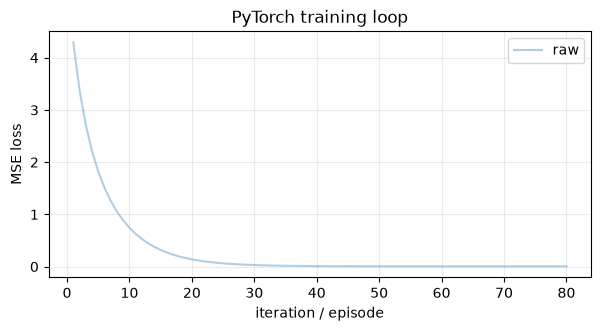

weight/bias: 2.478 -0.396


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


import torch

torch.manual_seed(3)
x = torch.linspace(-1, 1, 96).unsqueeze(1)
y = 2.5 * x - 0.4 + 0.08 * torch.randn_like(x)
model = torch.nn.Linear(1, 1)
optimizer = torch.optim.SGD(model.parameters(), lr=0.12)
losses = []
for _ in range(80):
    pred = model(x)
    loss = torch.nn.functional.mse_loss(pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

plot_curve(losses, "PyTorch training loop", "MSE loss")
print("weight/bias:", round(model.weight.item(), 3), round(model.bias.item(), 3))


### 曲线怎么读

loss 应先快后慢下降，参数接近 2.5 和 -0.4。若 loss 完全不变，优先检查梯度是否存在、optimizer 是否拿到模型参数、`step()` 是否执行。

### 调参过程：一次只改变一个因素

- 先用小模型和 SGD 验证数据、梯度、loss 能下降。
- 学习率按 10 倍尺度尝试：0.01、0.1、1.0，找稳定下降区间。
- 再加入隐藏层或 Adam；每次只改变一个因素。

### 失败案例复盘

- 忘记 `zero_grad()`，梯度跨 batch 意外累加。
- 在 forward 中调用 `.detach()`，计算图被切断。
- 只看最后一个 batch 的 loss，把随机波动误当整体趋势。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 始终在关键边界打印或断言 shape；多数 RL bug 是 batch 维度错误。
- 评估时使用 `model.eval()` 与 `torch.no_grad()`。
- 把 tensor 转 NumPy 前通常先 `.detach().cpu()`。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

把模型改成 `Linear(1, 16) → ReLU → Linear(16, 1)`，比较收敛速度和最终误差。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

MLP 可写成 `nn.Sequential(nn.Linear(1,16), nn.ReLU(), nn.Linear(16,1))`。相同数据下它也能拟合直线，但参数更多，不保证比线性模型更快；比较时固定 seed，并记录每 20 步 loss，而不是只看最后一次。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- 网络训练始终围绕前向、损失、反向、更新四步。
- 梯度是局部方向，不保证任意大学习率都稳定。
- shape、dtype、device 是 PyTorch 调试三件套。
- RL 只是在目标数据的产生方式上比监督学习更复杂。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**`.backward()` 会直接更新模型权重吗？为什么训练循环需要 `zero_grad()`？

<details>
<summary>展开答案</summary>

不会；它只计算并累积梯度。`step()` 才更新权重。因为 PyTorch 默认累积 `.grad`，每个独立 batch 前通常要清零。
</details>


## 17. 与前后章节连接

第 4 章将网络输出解释为动作 logits；第 6 章将同一训练循环用于拟合 TD target。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

TensorBoard 用于曲线监控；Ignite 封装事件循环；GAN 示例用于练习更复杂的训练组织，而不是本章 RL 主线。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-03) · [← 学习索引](../README.md)
